# The RCS ramp, studied from a notebook

The rapid cycling synchrotron takes the electrons from 0.75 GeV to 9 GeV in about 108 ms (ADR 0013).
This notebook ramps a virtual RCS and looks at what its BPMs recorded on every turn of the ramp:
the tunes as the energy rises, the orbit, the beam lost, and the bunch extracted.

It uses only the library (`eicvibe.notebook`, ADR 0016). Each step is one you can change: the
ramp profile, the beam, the engine, the analysis.

**Before you start.** Run it with the EICViBE kernel (`uv run jupyter lab` in the checkout). Set
`EICVIBE_MACHINE` to the EIN machine folder if it is not where the next cell looks. With TrackPad, a ramp
of 16 particles takes about a minute on a laptop; with Xsuite, several.

In [1]:
import os
import time
from pathlib import Path

import numpy as np

import eicvibe.notebook as ev

MACHINE = Path(os.environ.get("EICVIBE_MACHINE", "../../virtual_accelerator/EIN/machine"))
RUNS = Path(os.environ.get("EICVIBE_RUNS", "runs"))  # each run writes a folder here
ENGINE = "trackpad" if ev.engine("trackpad").available() else "xsuite"
PARTICLES = 16

m = ev.machine(MACHINE)
m

Machine ein
  folder   ../../virtual_accelerator/EIN/machine
  routes   direct, bar
  devices  855, 2,280 channels
  branch    kind  length (m)  elements  BPMs  energy (GeV)  ramp  beam                    
  ltr       line  63.684      61        15    0.75          –     19,998 particles, 1.7 nC
  itl       line  11.176      19        4     0.75          –     –                       
  bar       ring  36.521      51        10    0.75          –     –                       
  etl       line  11.176      19        4     0.75          –     –                       
  rcs       ring  1506.93     917       192   0.75          rcs   –                       
  rte       line  126.91      51        0     10            –     –                       
  prj       line  76.765      126       23    0.000831369   –     –                       
  prj_gun   line  1.601       9         1     0.000831369   –     –                       
  prj_spin  line  3.15        8         1     0.000831369   –     –

## The ramp profile

The machine folder's `ramps/rcs.yaml` gives the energy waveform (a smooth start, a linear ramp, a
smooth end) and the RF program: the cavities' total voltage and the synchronous phase, which give the
energy each turn gains and the radiation takes.

In [2]:
profile = m.ramps["rcs"]
profile

energy,0.75 → 9 GeV
linear ramp,"86.25 GeV/s to 8.813 GeV, after 4000 turns"
flattop,10 ms
RF voltage,1.698 … 15.92 MV
synchronous phase,up to 52.5°
cavities,all of the ring's
source,03_RCS Parameter Database.xlsx


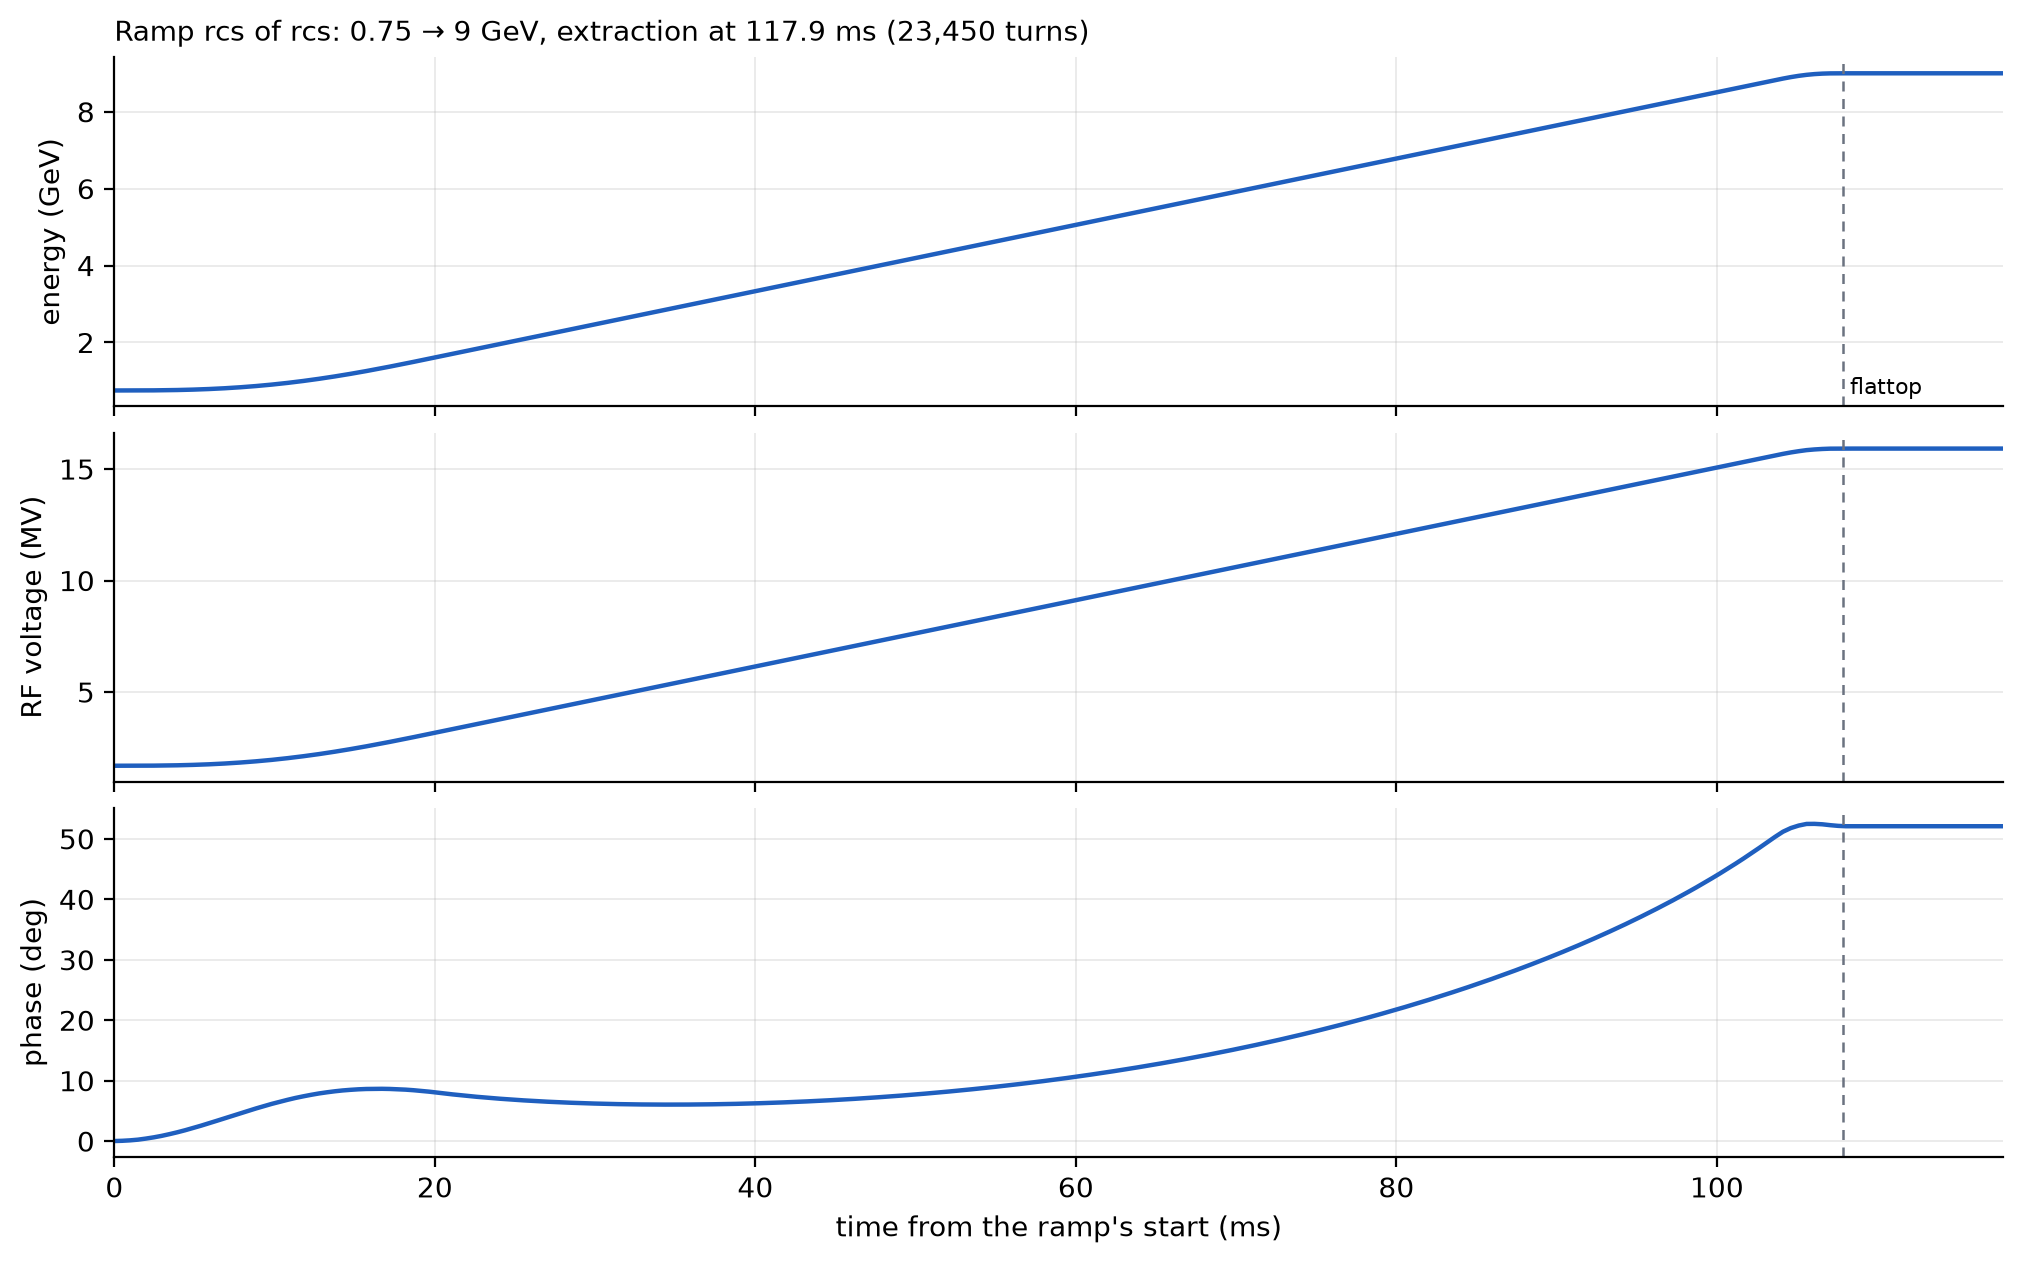

In [3]:
ev.plot_ramp(profile, m)

## The ring at injection

The optics the bunch is matched to, in the viewer's own optics view: hover for values, drag to
zoom, click an element; `view.selected` and `view.s_range` tell Python what you picked, and
`view.zoom(s0, s1)` moves it.

In [4]:
injection = ev.optics(m, "rcs", engine=ENGINE)
view = ev.OpticsView(m, "rcs", result=injection, s=(0, 220))
view

Each of the viewer's views is a widget of its own: the floor plan too. `ev.link` ties views as
the page's are (the branch shown, the selection, the s range): pick a magnet in either, and the other
shows it.

In [ ]:
floor = ev.FloorView(m, "rcs", height=320)
ev.link(view, floor)
floor

## A ring that ramps

`start_ring` starts the virtual RCS with the machine's BPMs and its ramp profile; it tracks in a
worker process of its own, in the background, and holds its bunch at injection until it is told to
ramp. The kick before the ramp starts a betatron oscillation, so the BPMs see the tunes all the way up.

In [5]:
run = ev.start_ring(m, "rcs", RUNS / f"rcs-ramp-{time.strftime('%Y%m%d-%H%M%S')}",
                   engine=ENGINE, beam=ev.Beam(particles=PARTICLES))
run.wait(2048)  # some turns at injection first
run.kick(x=40e-6, y=40e-6)
run.ramp()
run

folder,runs/rcs-ramp-20261021-111448
engine,trackpad
state,"running at turn 2,224"
ramp,"rcs: injection, 0.75 GeV"
tune monitor,"0.2003, 0.4376"


The run's BPM orbits, live while it ramps. The next cell waits for extraction; run it once you
have watched, as the view is answered only while no cell runs.

In [6]:
ev.OrbitView(m, "rcs", runs=[run])

In [7]:
def extracted(run) -> bool:
    return any(e["kind"] == "extract" for e in run.history.events())


while not extracted(run):
    if run.error:
        raise run.error
    cycle = run.cycle
    print(f"turn {run.turn:>7,}  {cycle['state']:<9} {cycle['energy'] / 1e9:6.3f} GeV", end="\r")
    time.sleep(2)
run.stop()
history = run.history
history

folder,runs/rcs-ramp-20261021-111448
engine,trackpad standard
state,"stopped at turn 27,048"
kept turn by turn,"22,904 to 27,048"
captures,4
BPMs,192
ramp,rcs


## What the ramp did

The run's events say when the ramp began, reached the flattop and extracted, and what the bunch was
like at extraction (emittances at the ring's start, with dispersion).

In [8]:
import pandas as pd


def row(event: dict) -> dict:
    energy = event.get("energy", event.get("injection"))
    scaled = lambda key, factor: event[key] * factor if key in event else None  # noqa: E731
    return {
        "turn": event["turn"],
        "event": event["kind"],
        "energy (GeV)": energy / 1e9 if energy else None,
        "particles": event.get("particles"),
        "εx (nm)": scaled("emittance_x", 1e9),
        "εy (pm)": scaled("emittance_y", 1e12),
        "σδ (10⁻³)": scaled("sigma_delta", 1e3),
        "σz (mm)": scaled("sigma_zeta", 1e3),
    }


kinds = ("inject", "kick", "ramp", "flattop", "extract")
pd.DataFrame([row(e) for e in history.events() if e["kind"] in kinds]).set_index("turn").round(4).fillna("")

,event,energy (GeV),particles,εx (nm),εy (pm),σδ (10⁻³),σz (mm)
turn,,,,,,,
0,inject,,16.0,,,,4.9497
2411,kick,,,,,,
2411,ramp,0.75,,,,,
23872,flattop,9.0,,,,,
25861,extract,9.0,15.0,38.9885,0.0073,0.98,15.8335
25861,inject,,16.0,,,,4.9497


## Every turn of the ramp

At extraction the BPMs' readings of every turn of the ramp are kept as a capture. The same
analysis reads it as it reads a measured turn-by-turn file.

In [9]:
[capture] = [c for c in history.captures() if c["kind"] == "ramp"]
tbt = history.capture(capture["id"])
ramp = history.info.ramp
start = next(e["turn"] for e in history.events() if e["kind"] == "ramp")
tbt

source,"virtual rcs run rcs-20261021T151456 (trackpad, standard), capture 000000002411-ramp (ramp)"
turns,"2,411 to 25,861 (23,450)"
BPMs,"192 x, 192 y; 100.0% of the x readings valid"
first turn at,2026-10-21 15:14:56
events,"6: capture, flattop, kick, loss, ramp"


The fractional tunes over the ramp, from 1024-turn stretches, against the energy: the magnets
follow the energy, so the tunes should stay where they were at injection. Near the top the
radiation damps the kick's oscillation to the BPMs' noise (a few µm): the strongest line left is then
no longer the betatron tune, but the synchrotron line in x (the energy oscillation, seen through the
dispersion) and noise in y. A tune monitor keeps exciting the beam for that reason.

In [10]:
stretch = 1024
first, qx, ax = ev.tune_drift(tbt.x, stretch, stretch)
_, qy, ay = ev.tune_drift(tbt.y, stretch, stretch)
turn = tbt.first_turn + first + stretch // 2 - start
energy = np.array([profile.energy.energy(t, ramp["period"]) / 1e9 for t in turn])
model = (injection.tune_x % 1, injection.tune_y % 1)
ev.chart(
    {"qx": (energy, qx), "qy": (energy, qy)},
    title="Tunes along the ramp (one pickup reads q or 1 - q: between 0 and 0.5)",
    x_label="energy (GeV)", y_label="fractional tune", style="both", y_zero=False,
    markers=[{"y": min(q, 1 - q), "label": f"model {min(q, 1 - q):.4f}"} for q in model],
)

The oscillation's amplitude shrinks as the energy rises (adiabatic damping, as 1/√p) and as the
electrons radiate; the bunch's charge at the BPMs shows any loss.

In [11]:
charge = np.nanmedian(tbt.x.intensity, axis=0)  # nC, the BPMs' median, turn by turn
turns = np.arange(tbt.turns)
every = slice(None, None, 64)
ev.chart({"x": (energy, ax), "y": (energy, ay)}, title="Oscillation amplitude along the ramp",
         x_label="energy (GeV)", y_label="amplitude (mm)", style="both")

In [12]:
ev.chart({"charge": (turns[every] * ramp["period"] * 1e3, charge[every])},
         title="Bunch charge at the BPMs", x_label="time from the ramp's start (ms)", y_label="charge (nC)",
         markers=[{"x": ramp["flattop_turn"] * ramp["period"] * 1e3, "label": "flattop"}], y_zero=False)

## Next

- Change the RF program (`profile.rf`) or the beam (`ev.Beam(...)`) and ramp again.
- More particles: give `start_ring` a `host=` to track on a GPU or many cores (ADR 0015).
- Compare TrackPad and Xsuite: `engine="xsuite"`.